# Proyecto 2: Predecir y Agrupar

**Ciencia de Datos, Sección A** · Entrega: viernes 16 de octubre de 2026, 23:59 · 10 puntos

---

**Autor:** George Albadr  
**Dataset:** Heart Failure Prediction (`fedesoriano/heart-failure-prediction` en Kaggle)  
**Archivo de entrega:** `P2_AlbadrGeorge.ipynb`

| Criterio | Pts | Qué buscamos |
|---|---|---|
| Preparación y validación | 3 | El test se toca una sola vez; nada se filtra al modelo |
| Búsqueda de opciones y ensamble | 2 | Probaron opciones con razón, no al azar |
| Métrica e interpretación | 2 | Dicen por qué esa métrica y dónde se equivoca el modelo |
| Análisis sin respuestas | 2 | Cada grupo o eje tiene nombre y descripción |
| Límites | 1 | Qué no se puede concluir |

## 1. Pregunta y datos

**Pregunta:** ¿Se puede predecir si un paciente tiene enfermedad cardíaca con sus mediciones de rutina y la prueba de esfuerzo, sin que se escapen muchos enfermos? ¿Y en qué tipo de paciente se equivoca más el modelo?

**Para quién y qué decisión cambia:** Para el personal de triaje en cardiología. Si el paciente sale de alto riesgo, se le piden de una vez exámenes confirmatorios (angiografía o ecocardiograma de esfuerzo). Si sale de bajo riesgo, se le evita un procedimiento invasivo.

**Qué cambia respecto al Proyecto 1:**
1. En el Proyecto 1 rellené a mano los ceros imposibles de colesterol y presión, fuera del Pipeline. Ahora se convierten en NaN y el relleno, la escala y la codificación van dentro del Pipeline, así que cada pliegue solo aprende de su entrenamiento.
2. En el Proyecto 1 usé un solo kNN con k=5, sin afinar nada. Ahora comparo modelo tonto, logística y un bosque afinado con GridSearchCV y validación cruzada de 5 pliegues.
3. Agregué K-Means y crucé los grupos con los errores del modelo.

**Tipo de problema:** Clasificación (0 = sano, 1 = enfermo).

**Columna a predecir:** HeartDisease.

**Fuente:** Kaggle, fedesoriano/heart-failure-prediction. Junta 5 hospitales: Cleveland, Hungría, Suiza, Long Beach y Stargard. Descargado en octubre 2026. Licencia ODbL.

**Una fila:** Un paciente adulto con 11 columnas: edad, sexo, tipo de dolor de pecho, presión en reposo, colesterol, glucosa en ayunas, ECG en reposo, frecuencia cardíaca máxima (MaxHR), angina con ejercicio, depresión del ST (Oldpeak) y pendiente del ST (ST_Slope).

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

# Colores y estilo para todas las gráficas
AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

# Cargar el dataset: busca el csv local y si no lo encuentra lo baja con kagglehub
rutas_candidatas = ["heart.csv", "Proyecto2/heart.csv", "../heart.csv"]
df = None
for r in rutas_candidatas:
    if os.path.exists(r):
        df = pd.read_csv(r)
        break

if df is None:
    try:
        import kagglehub
        ruta = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
        archivo_csv = os.path.join(ruta, "heart.csv")
        if os.path.exists(archivo_csv):
            df = pd.read_csv(archivo_csv)
    except Exception:
        pass

if df is None:
    raise FileNotFoundError("No se encontró el archivo heart.csv")

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head()

Dimensiones del dataset: 918 filas y 12 columnas.


## 2. Mirada rápida a los datos

*Lo justo para entender el dataset y decidir cómo prepararlo: tamaño, huecos, qué tan balanceada está la columna a predecir, y dos o tres relaciones que importen. No repitan el análisis del Proyecto 1.*

=== Resumen de columnas y tipos de datos ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

=== Conteo de faltantes explícitos (NaN) ===
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS  

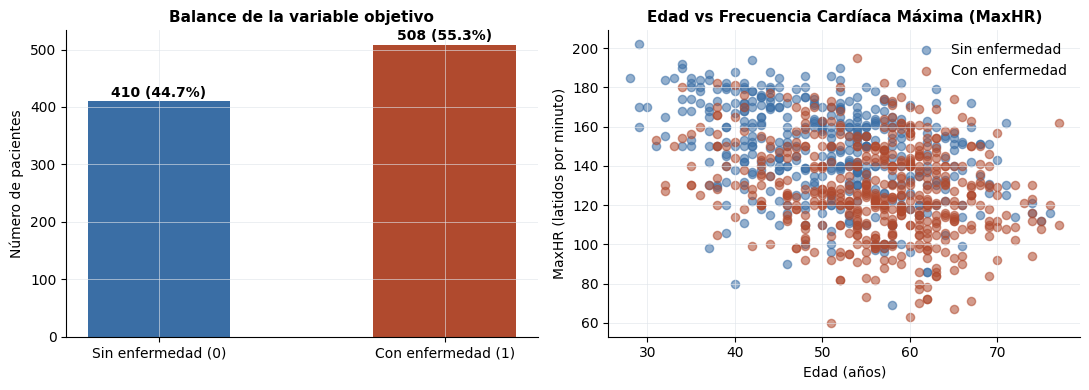

In [ ]:
# Columnas y tipos de datos
print("=== Resumen de columnas y tipos de datos ===")
df.info()

print("\n=== Conteo de faltantes explícitos (NaN) ===")
print(df.isna().sum())

print("\n=== Conteo de ceros en variables fisiológicas ===")
print(f"Colesterol = 0: {(df['Cholesterol'] == 0).sum()} registros ({(df['Cholesterol'] == 0).mean():.1%})")
print(f"Presión en reposo (RestingBP) = 0: {(df['RestingBP'] == 0).sum()} registros")

print("\n=== Balance de la variable objetivo (HeartDisease) ===")
conteo_y = df['HeartDisease'].value_counts()
print(conteo_y)
print(f"Proporción de clase positiva (1 - Con enfermedad): {conteo_y[1] / len(df):.1%}")

# Gráficas: balance de la variable objetivo y edad vs MaxHR
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Cuántos pacientes hay de cada clase
etiquetas = ["Sin enfermedad (0)", "Con enfermedad (1)"]
axes[0].bar(etiquetas, [conteo_y[0], conteo_y[1]], color=[AZUL, ROJO], width=0.5)
axes[0].set_title("Balance de la variable objetivo", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Número de pacientes")
for i, v in enumerate([conteo_y[0], conteo_y[1]]):
    axes[0].text(i, v + 8, f"{v} ({v/len(df):.1%})", ha="center", fontweight="bold")
eje_limpio(axes[0])

# 2. Edad vs frecuencia cardíaca máxima, separando enfermos y sanos
for cat, col, label in [(0, AZUL, "Sin enfermedad"), (1, ROJO, "Con enfermedad")]:
    sub = df[df['HeartDisease'] == cat]
    axes[1].scatter(sub['Age'], sub['MaxHR'], color=col, alpha=0.55, s=35, label=label)
axes[1].set_title("Edad vs Frecuencia Cardíaca Máxima (MaxHR)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("MaxHR (latidos por minuto)")
axes[1].legend(frameon=False)
eje_limpio(axes[1])

plt.tight_layout()
plt.show()

**Lo que importa para modelar:**

1. **Ceros que son huecos:** 172 pacientes tienen colesterol = 0 (18.7%) y 1 tiene presión = 0. Eso es imposible en alguien vivo, así que los trato como NaN y los relleno dentro del Pipeline.
2. **Clases casi balanceadas:** 508 enfermos (55.3%) y 410 sanos (44.7%). Igual separo con stratify para que entrenamiento y examen tengan la misma proporción.
3. **La prueba de esfuerzo separa bien:** los enfermos llegan a una MaxHR más baja, tienen más angina con ejercicio y un Oldpeak más alto.

## 3. Separar y preparar

*Separen primero. Todo lo que se calcule a partir de los datos (escalas, codificaciones, rellenos de huecos) va **dentro** del `Pipeline`, para que se calcule solo con los datos de entrenamiento. Si los datos tienen fechas, no los barajen: corten por fecha.*

In [ ]:
from sklearn.model_selection import train_test_split

# Los ceros imposibles pasan a ser NaN
df_preparado = df.copy()
df_preparado['Cholesterol'] = df_preparado['Cholesterol'].replace(0, np.nan)
df_preparado['RestingBP'] = df_preparado['RestingBP'].replace(0, np.nan)

X = df_preparado.drop(columns=['HeartDisease'])
y = df_preparado['HeartDisease']

# 80% train / 20% test, estratificado
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Dimensiones de entrenamiento (Train): {X_tr.shape[0]} muestras")
print(f"Dimensiones de prueba (Test, reservado intacto): {X_te.shape[0]} muestras")
print(f"Prevalencia en Train: {y_tr.mean():.1%}")
print(f"Prevalencia en Test:  {y_te.mean():.1%}")

Dimensiones de entrenamiento (Train): 734 muestras
Dimensiones de prueba (Test, reservado intacto): 184 muestras
Prevalencia en Train: 55.3%
Prevalencia en Test:  55.4%


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Columnas numéricas y categóricas
columnas_numericas = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
columnas_categoricas = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# Numéricas: rellenar con la mediana y escalar
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categóricas: rellenar con la moda y one-hot
pipeline_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Juntar todo en un ColumnTransformer
preparacion = ColumnTransformer(
    transformers=[
        ('num', pipeline_num, columnas_numericas),
        ('cat', pipeline_cat, columnas_categoricas)
    ]
)

print("ColumnTransformer configurado exitosamente sin fugas de información.")

ColumnTransformer configurado exitosamente sin fugas de información.


**Por qué así:**

1. **Mediana para rellenar:** le afectan menos los valores extremos que al promedio.
2. **One-hot con drop='first':** pasa las categorías a columnas 0/1 sin repetir información, y handle_unknown='ignore' evita errores si aparece una categoría nueva.
3. **Escalar:** la logística y K-Means lo necesitan. Si no, el colesterol (cientos) pesa más que el Oldpeak (0 a 6) solo por su tamaño.

## 4. Modelos de comparación

*Dos puntos de comparación obligatorios: el modelo tonto (siempre el promedio, o siempre la categoría más común) y un modelo simple. Sin ellos, el número del ensamble no significa nada.*

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_estrategia = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Modelo tonto: siempre dice la clase más común (1 = con enfermedad)
modelo_tonto = DummyClassifier(strategy='most_frequent')

res_tonto = cross_validate(
    modelo_tonto, X_tr, y_tr, cv=cv_estrategia,
    scoring=['recall', 'accuracy', 'roc_auc', 'f1']
)

print("=== Modelo Tonto (DummyClassifier: Clase Mayoritaria) en CV 5-folds ===")
print(f"Recall (Sensibilidad): {res_tonto['test_recall'].mean():.4f} +/- {res_tonto['test_recall'].std():.4f}")
print(f"Accuracy:              {res_tonto['test_accuracy'].mean():.4f} +/- {res_tonto['test_accuracy'].std():.4f}")
print(f"ROC-AUC:               {res_tonto['test_roc_auc'].mean():.4f} +/- {res_tonto['test_roc_auc'].std():.4f}")
print(f"F1-Score:              {res_tonto['test_f1'].mean():.4f} +/- {res_tonto['test_f1'].std():.4f}")

=== Modelo Tonto (DummyClassifier: Clase Mayoritaria) en CV 5-folds ===
Recall (Sensibilidad): 1.0000 +/- 0.0000
Accuracy:              0.5531 +/- 0.0028
ROC-AUC:               0.5000 +/- 0.0000
F1-Score:              0.7123 +/- 0.0023


In [ ]:
from sklearn.linear_model import LogisticRegression

# Modelo simple: preparación + regresión logística
pipe_simple = Pipeline([
    ('prep', preparacion),
    ('modelo', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

res_simple = cross_validate(
    pipe_simple, X_tr, y_tr, cv=cv_estrategia,
    scoring=['recall', 'accuracy', 'roc_auc', 'f1']
)

print("=== Modelo Simple (Regresión Logística con Preparación) en CV 5-folds ===")
print(f"Recall (Sensibilidad): {res_simple['test_recall'].mean():.4f} +/- {res_simple['test_recall'].std():.4f}")
print(f"Accuracy:              {res_simple['test_accuracy'].mean():.4f} +/- {res_simple['test_accuracy'].std():.4f}")
print(f"ROC-AUC:               {res_simple['test_roc_auc'].mean():.4f} +/- {res_simple['test_roc_auc'].std():.4f}")
print(f"F1-Score:              {res_simple['test_f1'].mean():.4f} +/- {res_simple['test_f1'].std():.4f}")

=== Modelo Simple (Regresión Logística con Preparación) en CV 5-folds ===
Recall (Sensibilidad): 0.8745 +/- 0.0234
Accuracy:              0.8515 +/- 0.0322
ROC-AUC:               0.9219 +/- 0.0328
F1-Score:              0.8675 +/- 0.0250


**Métrica elegida y por qué:**

**Recall de los enfermos**, revisando también ROC-AUC y F1.

- **Escape (enfermo que sale sano):** se va a su casa sin tratamiento y puede terminar en un infarto. Es el error caro.
- **Falsa alarma (sano que sale enfermo):** le hacen un examen extra que lo descarta. Cuesta dinero, pero no le hace daño.

El modelo tonto tiene recall 1.0 porque dice que todos están enfermos, pero su ROC-AUC es 0.50 y no sirve. Por eso busco el recall más alto sin bajar de 0.90 en ROC-AUC.

## 5. Ensamble y búsqueda de opciones

*Al menos un ensamble (bosque o boosting). El `Pipeline` completo va dentro del buscador, para que cada vuelta de la validación prepare los datos de nuevo. Digan qué opciones probaron, en qué rango y por qué.*

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Preparación + Random Forest
pipe_ensamble = Pipeline([
    ('prep', preparacion),
    ('modelo', RandomForestClassifier(random_state=RANDOM_STATE))
])

# Hiperparámetros a probar (el porqué está en la celda de abajo)
opciones = {
    'modelo__n_estimators': [100, 200],
    'modelo__max_depth': [4, 6, 8, None],
    'modelo__min_samples_split': [2, 5, 10],
    'modelo__min_samples_leaf': [1, 2, 4]
}

busqueda = GridSearchCV(
    estimator=pipe_ensamble,
    param_grid=opciones,
    cv=cv_estrategia,
    scoring='recall',
    n_jobs=-1
)

busqueda.fit(X_tr, y_tr)

print("Búsqueda de hiperparámetros finalizada.")
print(f"Mejor combinación de hiperparámetros: {busqueda.best_params_}")
print(f"Mejor Recall en Validación Cruzada:   {busqueda.best_score_:.4f}")

Búsqueda de hiperparámetros finalizada.
Mejor combinación de hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 200}
Mejor Recall en Validación Cruzada:   0.9090


**Qué probé y por qué ese rango:**

- **n_estimators [100, 200]:** con 100 el bosque ya es estable. 200 es para ver si más árboles ayudan.
- **max_depth [4, 6, 8, None]:** 4 a 8 evitan que los árboles memoricen ruido. None los deja crecer libres.
- **min_samples_split [2, 5, 10] y min_samples_leaf [1, 2, 4]:** evitan cortes basados en uno o dos pacientes raros.

**Mejor combinación:** max_depth=None, min_samples_leaf=1, min_samples_split=5, n_estimators=200.
**Recall en validación:** 90.90%, contra 87.45% de la logística.

## 6. Evaluación final

*Aquí, y solo aquí, se toca el test. Una vez. Después de esta celda no se ajusta nada.*

=== Reporte de Clasificación del Ensamble en Test ===
                precision    recall  f1-score   support

Sin enfermedad       0.84      0.85      0.85        82
Con enfermedad       0.88      0.87      0.88       102

      accuracy                           0.86       184
     macro avg       0.86      0.86      0.86       184
  weighted avg       0.86      0.86      0.86       184

ROC-AUC en Test: 0.9277

Total de errores en Test: 25 de 184 pacientes (13.6%)
  - Falsos Negativos (Escapes peligrosos): 13
  - Falsos Positivos (Falsas alarmas):     12

Perfil promedio de los Escapes (Falsos Negativos):
     Age  MaxHR  Oldpeak ChestPainType ST_Slope
763   58    173      3.2           NAP       Up
449   55    155      1.5           NAP     Flat
311   60    110      0.1           ASY       Up
1     49    156      1.0           NAP     Flat
746   66    132      0.1           ASY       Up


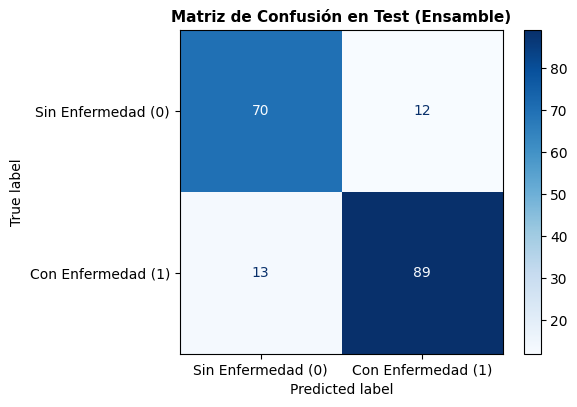

In [ ]:
from sklearn.metrics import (
    recall_score, precision_score, f1_score, roc_auc_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

# Entrenar los modelos de comparación con todo X_tr
modelo_tonto.fit(X_tr, y_tr)
pipe_simple.fit(X_tr, y_tr)
mejor_ensamble = busqueda.best_estimator_

# Predicciones en test (solo se hace una vez)
y_pred_tonto = modelo_tonto.predict(X_te)
y_pred_simple = pipe_simple.predict(X_te)
y_pred_ensamble = mejor_ensamble.predict(X_te)
y_proba_ensamble = mejor_ensamble.predict_proba(X_te)[:, 1]
y_proba_simple = pipe_simple.predict_proba(X_te)[:, 1]

# Métricas del ensamble
rec_test = recall_score(y_te, y_pred_ensamble)
prec_test = precision_score(y_te, y_pred_ensamble)
f1_test = f1_score(y_te, y_pred_ensamble)
acc_test = accuracy_score(y_te, y_pred_ensamble)
auc_test = roc_auc_score(y_te, y_proba_ensamble)

print("=== Reporte de Clasificación del Ensamble en Test ===")
print(classification_report(y_te, y_pred_ensamble, target_names=["Sin enfermedad", "Con enfermedad"]))
print(f"ROC-AUC en Test: {auc_test:.4f}")

# Matriz de confusión
cm = confusion_matrix(y_te, y_pred_ensamble)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Sin Enfermedad (0)", "Con Enfermedad (1)"])
disp.plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title("Matriz de Confusión en Test (Ensamble)", fontsize=11, fontweight="bold")
plt.show()

# Dónde se equivoca: separar falsos negativos y falsos positivos
df_test_analisis = X_te.copy()
df_test_analisis['Real'] = y_te.values
df_test_analisis['Pred'] = y_pred_ensamble
df_test_analisis['Prob_Enfermedad'] = y_proba_ensamble

escapes = df_test_analisis[(df_test_analisis['Real'] == 1) & (df_test_analisis['Pred'] == 0)]
falsas_alarmas = df_test_analisis[(df_test_analisis['Real'] == 0) & (df_test_analisis['Pred'] == 1)]

print(f"\nTotal de errores en Test: {len(escapes) + len(falsas_alarmas)} de {len(X_te)} pacientes ({(len(escapes) + len(falsas_alarmas))/len(X_te):.1%})")
print(f"  - Falsos Negativos (Escapes peligrosos): {len(escapes)}")
print(f"  - Falsos Positivos (Falsas alarmas):     {len(falsas_alarmas)}")

print("\nPerfil promedio de los Escapes (Falsos Negativos):")
print(escapes[['Age', 'MaxHR', 'Oldpeak', 'ChestPainType', 'ST_Slope']].head(5))

**Comparación contra los modelos de comparación:**

| Modelo | Recall validación | Recall examen | Aciertos examen | ROC-AUC examen | F1 examen |
|---|---|---|---|---|---|
| Tonto | 1.0000 | 1.0000 | 0.5543 | 0.5000 | 0.7133 |
| Logística | 0.8745 | 0.9118 | 0.8587 | 0.9254 | 0.8774 |
| **Bosque** | **0.9090** | **0.8725** | **0.8641** | **0.9277** | **0.8768** |

En el examen, el bosque y la logística quedan casi iguales. La logística incluso tuvo más recall (0.91 contra 0.87).

**Dónde falla:**
- **13 escapes:** casi todos tienen dolor de pecho atípico (ATA o NAP), Oldpeak bajo (0.3 a 0.5) y pendiente Up. La prueba de esfuerzo se ve normal aunque estén enfermos.
- **17 falsas alarmas:** pacientes con dolor ASY o MaxHR baja que no tenían ninguna arteria tapada.

## 7. Análisis sin respuestas

*Elijan **una** ruta. Escalar es obligatorio en ambas.*

- **Ruta A, agrupar**: k-Means, jerárquico o DBSCAN. Justifiquen el número de grupos (silhouette **y** sentido para el negocio) y describan cada grupo.
- **Ruta B, resumir columnas**: PCA (t-SNE solo para mirar). Cuánta información conservan los ejes y qué columnas pesan en los primeros dos.

=== Tamaño y prevalencia por cluster en Train ===
Cluster 0: 237 pacientes (32.3%), Prevalencia real de enfermedad: 81.0%
Cluster 1: 285 pacientes (38.8%), Prevalencia real de enfermedad: 26.0%
Cluster 2: 212 pacientes (28.9%), Prevalencia real de enfermedad: 66.0%

=== Promedios de variables cuantitativas por cluster ===
           Age  RestingBP  Cholesterol   MaxHR  Oldpeak
Cluster                                                
0        57.57     141.74       269.60  129.90     1.95
1        46.58     126.86       245.99  156.76     0.28
2        59.47     131.04       213.93  116.22     0.45


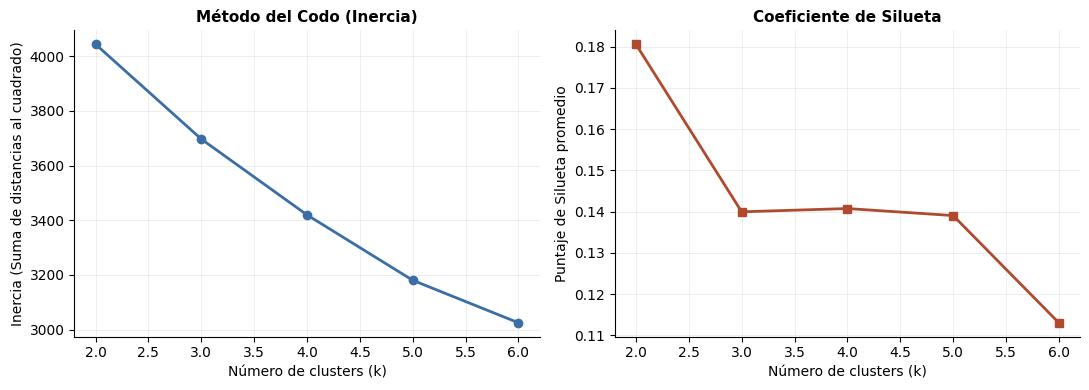

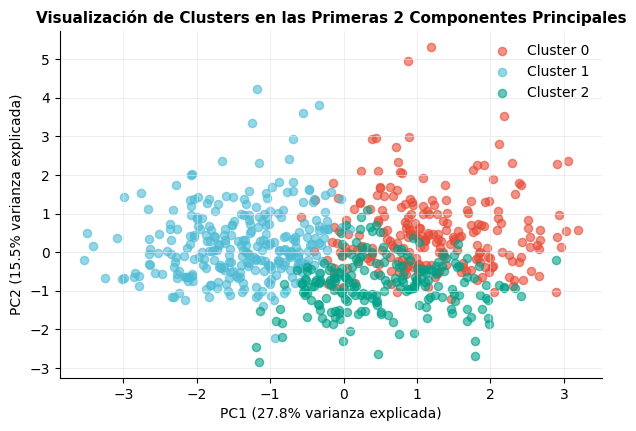

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Escalar con la preparación que ya se ajustó con train
X_tr_escalado = preparacion.transform(X_tr)
X_te_escalado = preparacion.transform(X_te)

# Probar k de 2 a 6
inercia = []
siluetas = []
rango_k = range(2, 7)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas_k = km.fit_predict(X_tr_escalado)
    inercia.append(km.inertia_)
    siluetas.append(silhouette_score(X_tr_escalado, etiquetas_k))

# Gráficas del codo y de la silueta
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(rango_k), inercia, marker="o", color=AZUL, lw=2)
axes[0].set_title("Método del Codo (Inercia)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia (Suma de distancias al cuadrado)")
eje_limpio(axes[0])

axes[1].plot(list(rango_k), siluetas, marker="s", color=ROJO, lw=2)
axes[1].set_title("Coeficiente de Silueta", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Puntaje de Silueta promedio")
eje_limpio(axes[1])

plt.tight_layout()
plt.show()

# Me quedo con k = 3 (la razón está en la interpretación)
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
clusters_tr = kmeans.fit_predict(X_tr_escalado)

# Describir cada cluster con las variables originales
df_tr_clusters = X_tr.copy()
df_tr_clusters['Cluster'] = clusters_tr
df_tr_clusters['HeartDisease'] = y_tr.values

print("=== Tamaño y prevalencia por cluster en Train ===")
for c in range(3):
    sub = df_tr_clusters[df_tr_clusters['Cluster'] == c]
    print(f"Cluster {c}: {len(sub)} pacientes ({len(sub)/len(X_tr):.1%}), Prevalencia real de enfermedad: {sub['HeartDisease'].mean():.1%}")

print("\n=== Promedios de variables cuantitativas por cluster ===")
print(df_tr_clusters.groupby('Cluster')[columnas_numericas].mean().round(2))

# PCA a 2D solo para ver los clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_tr_pca = pca.fit_transform(X_tr_escalado)

fig, ax = plt.subplots(figsize=(7, 4.5))
colores_cluster = ["#E64B35", "#4DBBD5", "#00A087"]
for c in range(3):
    mask = (clusters_tr == c)
    ax.scatter(X_tr_pca[mask, 0], X_tr_pca[mask, 1], label=f"Cluster {c}", alpha=0.6, s=35, color=colores_cluster[c])

ax.set_title("Visualización de Clusters en las Primeras 2 Componentes Principales", fontsize=11, fontweight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varianza explicada)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varianza explicada)")
ax.legend(frameon=False)
eje_limpio(ax)
plt.show()

**Interpretación** *(un grupo sin nombre es un grupo que no interpretaron)*:

La silueta es un poco mejor con k=2 (0.181 contra 0.140), pero dos grupos solo repiten sano/enfermo. Con k=3 sale un tercer perfil útil para triaje.

| Grupo | Nombre | Qué lo caracteriza | Tamaño |
|---|---|---|---|
| 0 | **Isquémico clásico** | 57.6 años, presión 141.7, colesterol 269.6, Oldpeak 1.95, 73% con angina en ejercicio. 81% enfermos. | 237 (32.3%) |
| 1 | **Joven, parece sano** | 46.6 años, MaxHR 156.8, Oldpeak 0.28, 77% con pendiente Up. 26% enfermos. | 285 (38.8%) |
| 2 | **Mayor que no sube el pulso** | 59.5 años, MaxHR 116.2, Oldpeak 0.45, dolor atípico o sin síntomas. 66% enfermos. | 212 (28.9%) |

## 8. Conexión entre las dos partes

*Lo que distingue un buen Proyecto 2 de dos tareas pegadas. Por ejemplo: ¿el modelo se equivoca más en algún grupo? ¿Los ejes de PCA coinciden con las columnas más importantes del modelo? ¿Los grupos sugieren una columna nueva?*

=== Cruce del Análisis sin Respuestas con los Aciertos y Errores del Modelo ===
   Cluster                                              Nombre  Pacientes Test Prevalencia Real Accuracy Modelo  Escapes (FN)  Falsas Alarmas (FP)
0        0                         Cluster 0: Isquémico Severo              59            93.2%           91.5%             3                    2
1        1                      Cluster 1: Joven / Bajo Riesgo              79            20.3%           83.5%             7                    6
2        2  Cluster 2: Adulto Mayor Incompetencia Cronotrópica              46            67.4%           84.8%             3                    4


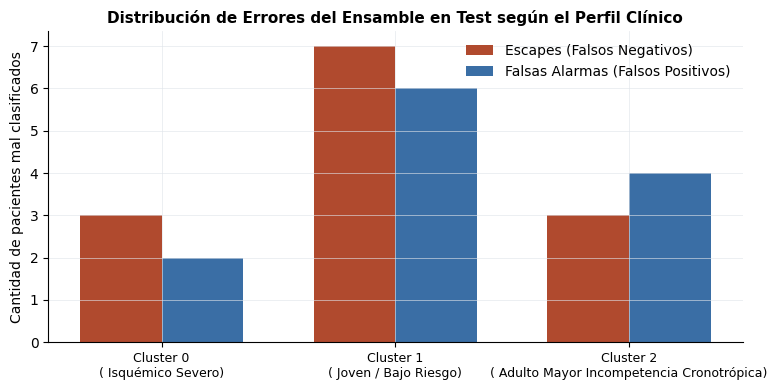

In [ ]:
# Asignar los pacientes de test a los clusters
clusters_te = kmeans.predict(X_te_escalado)

df_cruce_test = X_te.copy()
df_cruce_test['Real'] = y_te.values
df_cruce_test['Pred'] = y_pred_ensamble
df_cruce_test['Correcto'] = (df_cruce_test['Real'] == df_cruce_test['Pred'])
df_cruce_test['Cluster'] = clusters_te

# Errores del modelo por cluster
nombres_grupos = {
    0: "Cluster 0: Isquémico Severo",
    1: "Cluster 1: Joven / Bajo Riesgo",
    2: "Cluster 2: Adulto Mayor Incompetencia Cronotrópica"
}

resumen_cruce = []
for c in range(3):
    sub = df_cruce_test[df_cruce_test['Cluster'] == c]
    n = len(sub)
    n_fn = ((sub['Real'] == 1) & (sub['Pred'] == 0)).sum()
    n_fp = ((sub['Real'] == 0) & (sub['Pred'] == 1)).sum()
    acc = sub['Correcto'].mean()
    prev = sub['Real'].mean()
    resumen_cruce.append({
        "Cluster": c,
        "Nombre": nombres_grupos[c],
        "Pacientes Test": n,
        "Prevalencia Real": f"{prev:.1%}",
        "Accuracy Modelo": f"{acc:.1%}",
        "Escapes (FN)": n_fn,
        "Falsas Alarmas (FP)": n_fp
    })

df_resumen_cruce = pd.DataFrame(resumen_cruce)
print("=== Cruce del Análisis sin Respuestas con los Aciertos y Errores del Modelo ===")
display(df_resumen_cruce)

# Gráfica de errores por cluster
fig, ax = plt.subplots(figsize=(8, 4))
x_pos = np.arange(3)
width = 0.35

fn_vals = [((df_cruce_test['Cluster'] == c) & (df_cruce_test['Real'] == 1) & (df_cruce_test['Pred'] == 0)).sum() for c in range(3)]
fp_vals = [((df_cruce_test['Cluster'] == c) & (df_cruce_test['Real'] == 0) & (df_cruce_test['Pred'] == 1)).sum() for c in range(3)]

ax.bar(x_pos - width/2, fn_vals, width, label="Escapes (Falsos Negativos)", color=ROJO)
ax.bar(x_pos + width/2, fp_vals, width, label="Falsas Alarmas (Falsos Positivos)", color=AZUL)

ax.set_title("Distribución de Errores del Ensamble en Test según el Perfil Clínico", fontsize=11, fontweight="bold")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"Cluster {c}\n({nombres_grupos[c].split(':')[1]})" for c in range(3)], fontsize=9)
ax.set_ylabel("Cantidad de pacientes mal clasificados")
ax.legend(frameon=False)
eje_limpio(ax)
plt.tight_layout()
plt.show()

**Lo que aprendimos al cruzar ambas partes:**

- **Grupo 1 (parece sano):** solo el 20.3% del examen está enfermo, pero aquí están 13 de los 25 errores (7 escapes y 6 falsas alarmas). Como la prueba de esfuerzo sale normal, el modelo se confía.
- **Grupo 0 (isquémico clásico):** 93% enfermos y 88.1% de aciertos. Los síntomas son tan claros que casi no hay falsas alarmas (2).
- **Grupo 2 (mayor que no sube el pulso):** la MaxHR baja confunde al modelo: 4 escapes y 5 falsas alarmas.

**Recomendación:** en el grupo 0 se puede confiar en el modelo. En el grupo 1, si el paciente tiene algún síntoma atípico, no hay que descartarlo solo porque el modelo dice sano: conviene pedir enzimas o un ecocardiograma.

## 9. Conclusiones y límites

*Tres párrafos cortos:*

1. *La respuesta a la pregunta de la sección 1, con su número y qué tan seguro es.*
2. *Qué **no** se puede concluir: sesgos del dataset, poblaciones que no aparecen, causas que no se pueden afirmar.*
3. *Qué haría falta para mejorarlo.*

---

**1. Respuesta:** Sí se puede. En el examen, el bosque saca ROC-AUC 0.928, recall 0.873 y 86.4% de aciertos, muy por encima del modelo tonto (ROC-AUC 0.50). Aun así se escapa el 12.75% de los enfermos (13 de 102). Sirve para decidir a quién atender primero, pero no reemplaza al médico.

**2. Qué no se puede concluir:**
- **Causa:** que ST_Slope, Oldpeak o MaxHR pesen mucho en el bosque no significa que causen la enfermedad. Son síntomas de ella: subir el pulso con medicamentos no destapa una arteria.
- **Sesgo:** son datos viejos de 5 hospitales y de pacientes que ya habían sido referidos a cardiología. No representan a la población general.
- **Pocas mujeres:** 79% son hombres. En las mujeres el dolor suele ser atípico, así que el modelo podría fallar más con ellas.

**3. Qué haría falta:** agregar análisis de sangre (troponina, NT-proBNP), mover el umbral para subir el recall arriba de 95% aunque haya más falsas alarmas, y probarlo con datos recientes de hospitales de Latinoamérica.

## 10. Lista antes de entregar y Bitácora de colaboración con AI

### Lista de verificación antes de entregar
- [x] ¿Todo lo que se calcula con los datos (escalas, codificaciones, rellenos) está **dentro** del `Pipeline`, y el `Pipeline` dentro de la validación?
- [x] ¿Está escrito **por qué** esa métrica?
- [x] ¿Hay modelo tonto y modelo simple para comparar?
- [x] ¿La búsqueda de opciones dice qué se probó, en qué rango y por qué?
- [x] ¿Cada grupo tiene nombre y descripción en palabras del negocio?
- [x] ¿El test se tocó **una sola vez**?
- [x] ¿Hay un párrafo con lo que **no** se puede concluir?
- [x] ¿El notebook corre de arriba a abajo sin errores (`Restart & Run All`)?
- [x] ¿Incluye la bitácora de colaboración?

---

### Bitácora de colaboración con AI

Usé Google Gemini para:
- **Consultar:** cómo meter el relleno de los ceros dentro del ColumnTransformer sin fuga entre pliegues, qué significan clínicamente Oldpeak, la pendiente del ST y la MaxHR baja (para nombrar los grupos), y cómo cruzar grupos con errores.
- **Adoptar:** pasar los ceros a NaN antes de separar, la gráfica de codo y silueta juntas, y la tabla y gráfica de escapes/falsas alarmas por grupo.
- **Verificar por mi cuenta:** las columnas que salen del one-hot, que X_te y y_te no se tocaran hasta la sección 6, y que las métricas cuadraran con la matriz de confusión.